<sub>**The Annotated ML Handbook** · Part VIII: Debugging</sub>

# Chapter 34: When the code runs but the model is wrong

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Mahir-606/annotated-ml-handbook/blob/main/notebooks/part-8-debugging/34-debug-models.ipynb)

Companion code for the chapter. Every example from the book is here, in order, ready to run. The line-by-line explanations, definitions and discussion are in the book.

Run the setup cell first, then run the cells from top to bottom.

In [1]:
# Repository setup (not part of the book's examples): run this cell first.
import os, sys
from pathlib import Path

# Files the examples create (CSV, models, figures) go into ./outputs next to the notebook.
OUT = Path.cwd() if Path.cwd().name == "outputs" else Path.cwd() / "outputs"
OUT.mkdir(exist_ok=True)
os.chdir(OUT)

# insurance.csv is the practice dataset created in Chapter 11 and reused by later chapters.
# If it is not here yet, copy it from the repository's data/ folder (or download it in Colab).
if not Path("insurance.csv").exists():
    import shutil, urllib.request
    for base in OUT.parents:
        if (base / "data" / "insurance.csv").exists():
            shutil.copy(base / "data" / "insurance.csv", "insurance.csv")
            break
    else:
        try:
            urllib.request.urlretrieve("https://raw.githubusercontent.com/Mahir-606/"
                                       "annotated-ml-handbook/main/data/insurance.csv", "insurance.csv")
        except Exception as e:
            print("Could not fetch insurance.csv; run Chapter 11 first.", e)

# The figure style used in the book.
import matplotlib.pyplot as plt
from cycler import cycler
plt.rcParams.update({
    "figure.figsize": (7.2, 4.0), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.28, "grid.linewidth": 0.6,
    "axes.prop_cycle": cycler(color=["#1f4fff", "#e0245e", "#0f9b62", "#ff6a00",
                                     "#7b3ff2", "#0091b3", "#d99a00", "#d42a2a"]),
    "axes.titleweight": "bold", "axes.titlesize": 12.5, "axes.titlelocation": "left",
    "font.size": 10.5, "legend.frameon": False, "image.cmap": "viridis",
})

# Plotly: interactive in Jupyter/Colab; tools/run_all.py stores static PNGs so GitHub can show them.
try:
    import plotly.io as pio
    pio.renderers.default = os.environ.get("PLOTLY_RENDERER") or (
        "colab" if "google.colab" in sys.modules else "notebook_connected")
except ImportError:
    pass

## 34.1 Reading training curves · *Beginner*

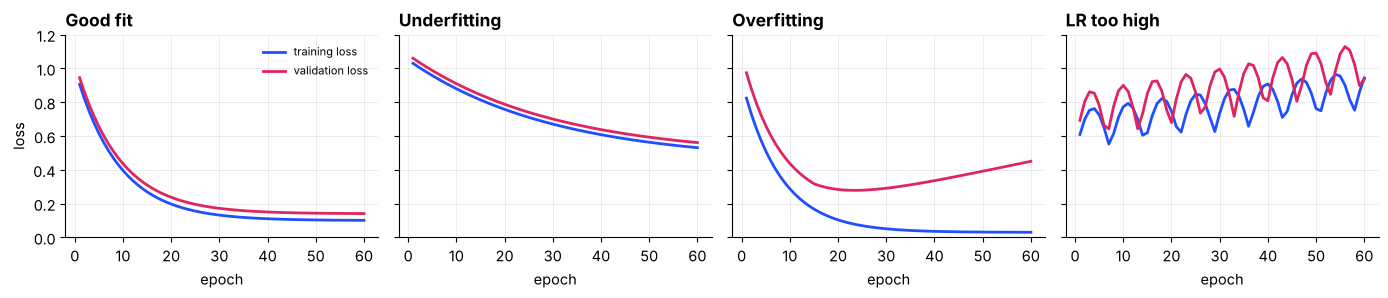

In [2]:
import numpy as np
import matplotlib.pyplot as plt
e = np.arange(1, 61)
fig, axes = plt.subplots(1, 4, figsize=(14, 3.1), sharey=True)
pats = {
    "Good fit": (0.9 * np.exp(-e / 9) + 0.10, 0.9 * np.exp(-e / 9) + 0.14),
    "Underfitting": (0.6 * np.exp(-e / 30) + 0.45, 0.6 * np.exp(-e / 30) + 0.48),
    "Overfitting": (0.9 * np.exp(-e / 8) + 0.03, 0.9 * np.exp(-e / 8) + 0.18 + 0.006 * np.clip(e - 15, 0, None)),
    "LR too high": (0.5 + 0.25 * np.abs(np.sin(e / 2.3)) + 0.004 * e, 0.55 + 0.3 * np.abs(np.sin(e / 2.1)) + 0.005 * e),
}
for ax, (title, (tr, va)) in zip(axes, pats.items()):
    ax.plot(e, tr, label="training loss", lw=2); ax.plot(e, va, label="validation loss", lw=2)
    ax.set(title=title, xlabel="epoch"); ax.set_ylim(0, 1.2)
axes[0].set_ylabel("loss"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 34.2 Symptom → likely cause → what to try · *Beginner*

## 34.3 Sanity checks that catch silent bugs · *Intermediate*

### 34.3.1 1. Can the model overfit a tiny subset?

**Overfit 32 samples on purpose**

In [3]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.datasets import load_digits

keras.utils.set_random_seed(0)
Xd, yd = load_digits(return_X_y=True)
X_small, y_small = (Xd[:32] / 16).astype("float32"), yd[:32]
net = keras.Sequential([keras.Input(shape=(64,)), layers.Dense(128, activation="relu"), layers.Dense(10, activation="softmax")])
net.compile(optimizer=keras.optimizers.Adam(1e-2), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
h = net.fit(X_small, y_small, epochs=150, verbose=0)
print(f"final training accuracy on 32 samples: {h.history['accuracy'][-1]:.3f} (should be ~1.0)")

I0000 00:00:1795691234.380030    3290 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1795691235.524837    3290 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


final training accuracy on 32 samples: 1.000 (should be ~1.0)


### 34.3.2 2. Are features and labels still aligned?

**Shuffling rows separately destroys the relationship**

In [4]:
import pandas as pd
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

X = pd.DataFrame(Xd / 16)
y = pd.Series(yd)
pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
good = cross_val_score(pipe, X, y, cv=3).mean()
y_misaligned = y.sample(frac=1, random_state=0).reset_index(drop=True)
bad = cross_val_score(pipe, X, y_misaligned, cv=3).mean()
print(f"aligned: {good:.3f} | misaligned labels: {bad:.3f} (chance = 0.10)")

aligned: 0.929 | misaligned labels: 0.102 (chance = 0.10)


### 34.3.3 3. What is the model actually predicting?

**Look at the distribution of predictions**

In [5]:
import numpy as np
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
Xi, yi = make_classification(n_samples=2000, weights=[0.95], random_state=0)
Xtr, Xte, ytr, yte = train_test_split(Xi, yi, stratify=yi, random_state=0)
pred = LogisticRegression(C=1e-4, max_iter=1000).fit(Xtr, ytr).predict(Xte)
print("predicted class counts [0, 1]:", np.bincount(pred, minlength=2))
print("true class counts      [0, 1]:", np.bincount(yte, minlength=2))
print("accuracy:", round(np.mean(pred == yte), 3), "<- looks fine, yet the model never predicts class 1")

predicted class counts [0, 1]: [500   0]
true class counts      [0, 1]: [473  27]
accuracy: 0.946 <- looks fine, yet the model never predicts class 1


### 34.3.4 4. Does the pipeline see what you think it sees?

**Print the transformed feature matrix once**

In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
ins = pd.read_csv("insurance.csv")
pre = ColumnTransformer([("num", SimpleImputer(strategy="median"), ["age", "bmi"]),
                         ("cat", OneHotEncoder(drop="if_binary", sparse_output=False), ["smoker", "region"])])
Xt = pre.fit_transform(ins)
print(pd.DataFrame(Xt, columns=pre.get_feature_names_out()).head(3).to_string())
print("any NaN left:", bool(np.isnan(Xt).any()), "| shape:", Xt.shape)

   num__age  num__bmi  cat__smoker_yes  cat__region_northeast  cat__region_northwest  cat__region_southeast  cat__region_southwest
0      58.0      27.9              0.0                    0.0                    1.0                    0.0                    0.0
1      26.0      39.4              0.0                    0.0                    1.0                    0.0                    0.0
2      19.0      34.6              0.0                    0.0                    0.0                    0.0                    1.0
any NaN left: False | shape: (1000, 7)


## 34.4 A pre-submission checklist · *Beginner*

## Try it yourself

1. Break the "overfit 32 samples" check on purpose (learning rate 1e-6, or the wrong loss) and watch it fail.
2. Introduce a leak into the insurance pipeline (add a feature equal to `charges` plus noise) and see how the permutation importance and test score react.
3. Apply the pre-submission checklist to your own current project.

Worked solutions: [solutions-parts-5-8.ipynb](../../solutions/solutions-parts-5-8.ipynb), section *Chapter 34*.